# Clasificación de alteraciones visibles en frutas mediante visión artificial y aprendizaje profundo

**Visión Artificial · Facultad de Minas, Universidad Nacional de Colombia – Sede Medellín**
**Reto 2 — Dataset de alteraciones poscosecha en frutas**

---

## Contenido

1. Introducción y objetivo
2. Frutas y clases del dataset
3. Cantidad de datos
4. Conjuntos de datos externos
5. Datos propios: adquisición de muestras y captura de imágenes
6. Clasificación manual de las imágenes
7. Partición del dataset: train, validation y test
8. Análisis exploratorio del dataset

## 1. Introducción y objetivo

Este notebook documenta la construcción del dataset del proyecto: de dónde provienen las imágenes, cómo se tomaron, cómo se clasificaron y cómo se dividieron para el entrenamiento.

El objetivo general del proyecto es desarrollar un sistema de visión computacional  para la detección temprana de enfermedades y alteraciones poscosecha en frutas de interés nacional.

El dataset combina dos tipos de fuentes:

- **Conjuntos de datos públicos** que aportan volumen y variedad de lesiones.
- **Fotografías propias**, tomadas por el equipo con condiciones de captura controladas, que aportan imágenes de frutas adquiridas en condiciones reales de comercialización.

Las frutas estudiadas son **mango, banano y fresa**. El modelo de esta entrega se centra en **mango y banano**; la fresa se organizó y documentó, pero no entra al modelo (sección 2.3).

## 2. Frutas y clases del dataset

Cada fruta tiene su propio conjunto de clases. Las clases se definieron a partir de la inspección visual de los síntomas externos y de las categorías disponibles en los conjuntos públicos.

En `dataset/` cada clase tiene su carpeta `dataset/<fruta>/<clase>/`; el nombre de la carpeta aparece entre paréntesis en cada tabla.


### 2.1. Mango

| Clase | Descripción |
|---|---|
| **Sano** (`sano`) | Frutos sin síntomas visibles de las enfermedades contempladas. |
| **Antracnosis** (`antracnosis`) | Asociada a hongos del género *Colletotrichum*. Lesiones necróticas oscuras, frecuentemente hundidas, que pueden extenderse sobre la superficie del fruto. |
| **Roña o sarna (*Scab*)** (`sarna`) | Lesiones superficiales de apariencia áspera, costrosa o corchosa. |
| **Pudrición del extremo del pedúnculo (*Stem End Rot*)** (`pudricion_pedunculo`) | Oscurecimiento y deterioro del tejido cercano al punto de inserción del pedúnculo. |

### 2.2. Banano

| Clase | Descripción |
|---|---|
| **Sano** (`sano`) | Frutos sin alteraciones visibles en la cáscara. |
| **Antracnosis** (`antracnosis`) | Asociada a *Colletotrichum musae*. Se reconoce por masas de esporas visibles y lesiones oscuras en la cáscara. |
| **Pecas** (`pecas`) | Pequeñas manchas marrones que aparecen en la cáscara durante la maduración. No es un fitopatógeno: corresponde a fisiología normal, y se incluye como categoría de deterioro para evitar confundirla con una lesión patológica. |
| **Daño mecánico** (`dano_mecanico`) | Alteraciones de la cáscara causadas por golpes, roces o manipulación, sin origen patológico. |

**Clase descartada: pudrición de corona.** Asociada a *Fusarium* y *Colletotrichum*, se reconoce por micelio visible en la zona de la corona. Se descartó del dataset; solo se habían reunido 36 imágenes, todas propias, que quedaron registradas en `dataset/excluidas.csv`.

### 2.3. Fresa

| Clase | Descripción |
|---|---|
| **Sana** (`sano`) | Frutos sin síntomas visibles de las alteraciones estudiadas. |
| **Antracnosis** (`antracnosis`) | Asociada a especies de *Colletotrichum*. Lesiones necróticas que pueden presentar hundimiento y tonalidades marrones oscuras. |
| **Moho gris** (`moho_gris`) | Asociado principalmente a *Botrytis cinerea*. Deterioro del tejido con crecimiento fúngico de aspecto grisáceo. |

La fresa se organizó y documentó con estas tres clases, pero no entra al modelo de esta entrega: cada clase proviene de una sola fuente (sana y moho gris, solo de fotos propias; antracnosis, solo de Roboflow), así que un modelo aprendería a distinguir la fuente y no la alteración (sección 8.12).

## 3. Cantidad de datos

Conteo del dataset final (`dataset/`), calculado en la sección 8.3 a partir de `dataset/etiquetas.csv`. Las 648 imágenes que no entraron, con el motivo de cada una, están en `dataset/excluidas.csv` (sección 8.11).

### 3.1. Total de imágenes por clase

**Mango**

| Clase | Imágenes propias | Imágenes externas | Total |
|---|---|---|---|
| Sano | 0 | 249 | 249 |
| Antracnosis | 0 | 252 | 252 |
| Roña o sarna | 0 | 300 | 300 |
| Pudrición del extremo del pedúnculo | 0 | 300 | 300 |
| **Total mango** | **0** | **1.101** | **1.101** |

**Banano**

| Clase | Imágenes propias | Imágenes externas | Total |
|---|---|---|---|
| Sano | 66 | 68 | 134 |
| Antracnosis | 108 | 625 | 733 |
| Pecas | 100 | 15 | 115 |
| Daño mecánico | 40 | 79 | 119 |
| **Total banano** | **314** | **787** | **1.101** |

**Fresa** (documentada, fuera del modelo de esta entrega)

| Clase | Imágenes propias | Imágenes externas | Total |
|---|---|---|---|
| Sana | 116 | 0 | 116 |
| Antracnosis | 0 | 110 | 110 |
| Moho gris | 53 | 0 | 53 |
| **Total fresa** | **169** | **110** | **279** |

### 3.2. Total general

| | Imágenes propias | Imágenes externas | Total | % propias |
|---|---|---|---|---|
| Mango | 0 | 1.101 | 1.101 | 0 % |
| Banano | 314 | 787 | 1.101 | 28,5 % |
| Fresa | 169 | 110 | 279 | 60,6 % |
| **Dataset completo** | **483** | **1.998** | **2.481** | **19,5 %** |

## 4. Conjuntos de datos externos

Para complementar las fotografías propias se utilizaron conjuntos de datos públicos: dos de Mendeley Data, para mango y banano, y uno de Roboflow, para la antracnosis de la fresa. Todos están orientados a visión artificial en agricultura, pero difieren en tamaño, proceso de generación, anotación y licencia, por lo que cada uno requirió una revisión individual y una armonización de sus categorías con las clases del proyecto.

### 4.1. Mango: MangoDHDS

| | |
|---|---|
| **Nombre** | MangoDHDS: A Dataset of Diseased and Healthy Mangoes of 1.5 K Images |
| **Autores** | Priyanka Barhate, Bhojraj Barhate y Makarand Joshi |
| **Publicación** | 16 de julio de 2025 |
| **Repositorio / DOI** | Mendeley Data · [10.17632/b4nrw5hyyc.1](https://doi.org/10.17632/b4nrw5hyyc.1) |
| **Licencia** | CC BY 4.0 |
| **Tamaño original** | 1.500 imágenes JPG de 256 × 256 px, en 5 categorías equilibradas de 300 imágenes |

**Adquisición original.** Imágenes recopiladas entre abril y julio de 2021, 2022 y 2023 en centros de investigación, instalaciones de maduración, explotaciones agrícolas y organizaciones del sector hortofrutícola de India, con cámaras de teléfonos inteligentes, fondos blancos y orientación de especialistas agrícolas y fitopatológicos.

**Categorías originales:** antracnosis, cancro bacteriano, roña o sarna, pudrición del extremo del pedúnculo y mango sano.

**Selección para este proyecto:** mango sano, antracnosis, roña o sarna y pudrición del extremo del pedúnculo. Se excluyó **cancro bacteriano**.

**Limitaciones:** el fondo blanco y la resolución reducida pueden no representar escenarios comerciales con fondos complejos, iluminación variable y distintos grados de deterioro.

### 4.2. Banano: Banana and Banana Leaf Dataset for Classification and Disease Detection

| | |
|---|---|
| **Nombre** | Banana and Banana Leaf Dataset for Classification and Disease Detection |
| **Autores** | Utsab Das, Showrov Azam y Md Abdullah Al Kafi |
| **Publicación** | 27 de febrero de 2025 |
| **Repositorio / DOI** | Mendeley Data · [10.17632/5nfjzntwd8.2](https://doi.org/10.17632/5nfjzntwd8.2) |
| **Licencia** | CC BY 4.0 |
| **Tamaño original** | 2.375 imágenes originales (*Raw Data*) y 9.513 aumentadas (*Augmented Data*): 11.888 en total |

**Categorías originales:** antracnosis, daños por insectos, alteraciones de la cáscara, sigatoka, marchitez de Panamá y frutos sanos, entre otras.

**Selección para este proyecto:** únicamente imágenes de **frutos**; se excluyeron las categorías exclusivas de hojas.

**Consideraciones:**

- Las imágenes aumentadas son transformaciones de las originales y **no son observaciones independientes**.
- Las pecas naturales de la maduración no deben confundirse con lesiones patológicas como *Black Pitting*.
- La descripción del repositorio no permite confirmar por sí sola qué categorías de interés están disponibles (por ejemplo, pudrición de corona), por lo que la selección final de clases se hizo inspeccionando los archivos y etiquetas descargados.

**Imágenes usadas:** 759, en tres clases del proyecto: antracnosis (613), daño mecánico (78) y sano (68). En todas el fruto aparece recortado sobre fondo negro (sección 8.8). Se identificaron por su tamaño (1000 × 750 px) y por el patrón de sus nombres de archivo.

**Pendiente:** confirmar si estas imágenes vienen de la carpeta *Raw Data* o de *Augmented Data* del repositorio.

### 4.3. Fresa: Strawberry Disease Detection Dataset with Hybrid Data Augmentation

> **Pendiente de confirmar.** Las 110 imágenes de antracnosis de fresa del dataset final se descargaron de Roboflow: sus nombres tienen el formato de exportación de Roboflow (`.rf.`) y miden 419 × 419 px. Falta confirmar el nombre y el enlace del dataset de Roboflow, y si corresponde al conjunto descrito en esta sección.

| | |
|---|---|
| **Nombre** | Strawberry Disease Detection Dataset with Hybrid Data Augmentation |
| **Autores** | Jorge Galarza-Falfan, Oscar Adrian Aguirre-Castro, Everardo Inzunza-Gonzalez y Enrique Efrén García-Guerrero |
| **Publicación** | 23 de septiembre de 2025 |
| **Repositorio / DOI** | Mendeley Data · [10.17632/k2ptxmfjhj.1](https://doi.org/10.17632/k2ptxmfjhj.1) |
| **Licencia** | CC BY-NC 4.0 (uso no comercial) |
| **Tamaño original** | 5.610 imágenes anotadas de 640 × 640 px, en 8 categorías |

Fue diseñado para **segmentación de instancias** (máscaras poligonales en formato COCO), por lo que fue necesario adaptarlo a un problema de clasificación de imágenes.

**Categorías originales:** mancha angular de la hoja, antracnosis del fruto, tizón floral, moho gris, fresa sana, mancha foliar, oídio del fruto y oídio de la hoja.

**Selección para este proyecto:** fresa sana, moho gris y antracnosis del fruto.

**Aumento de datos del repositorio:** incluye aumento tradicional (rotaciones, recortes, inversiones, brillo, contraste y color) y una estrategia híbrida con imágenes sintéticas generadas con DALL·E 3, incorporadas solo en entrenamiento. La documentación reporta 2.459 imágenes base, 1.559 por aumento tradicional y 1.018 sintéticas; su suma (5.036) no coincide con el total de 5.610, diferencia que debe aclararse inspeccionando los archivos.

### 4.4. Resumen de uso de las fuentes externas

| Fruta | Fuente | Clases tomadas | Imágenes usadas |
|---|---|---|---|
| Mango | MangoDHDS | Sano, antracnosis, roña, pudrición del extremo del pedúnculo | 1.101 |
| Banano | Banana and Banana Leaf Dataset | Sano, antracnosis, daño mecánico | 759 |
| Banano | Externa sin identificar (cámara OPPO) | Pecas | 15 |
| Banano | Externa sin identificar | Antracnosis (12) y daño mecánico (1) | 13 |
| Fresa | Roboflow | Antracnosis | 110 |
| **Total** | | | **1.998** |

De MangoDHDS se usan 1.101 de las 1.200 imágenes de las cuatro clases elegidas: las otras 99 son duplicados exactos que ya venían en el conjunto original. También se excluyeron 163 fotos de stock de banano sano tomadas de Kaggle, que estaban rotadas o volteadas y sin su imagen original.

**Pendiente:** identificar la fuente de las 28 imágenes externas de banano sin identificar.

### 4.5. Referencias

Barhate, P., Barhate, B., & Joshi, M. (2025). *MangoDHDS: A Dataset of Diseased and Healthy Mangoes of 1.5 K Images* (Version 1) [Dataset]. Mendeley Data. https://doi.org/10.17632/b4nrw5hyyc.1

Das, U., Azam, S., & Al Kafi, M. A. (2025). *Banana and Banana Leaf Dataset for Classification and Disease Detection* (Version 2) [Dataset]. Mendeley Data. https://doi.org/10.17632/5nfjzntwd8.2

Galarza-Falfan, J., Aguirre-Castro, O. A., Inzunza-Gonzalez, E., & García-Guerrero, E. E. (2025). *Strawberry Disease Detection Dataset with Hybrid Data Augmentation* (Version 1) [Dataset]. Mendeley Data. https://doi.org/10.17632/k2ptxmfjhj.1

## 5. Datos propios: adquisición de muestras y captura de imágenes

### 5.1. Adquisición de las frutas

Las muestras se adquirieron en establecimientos de comercialización del Valle de Aburrá: la **Plaza Minorista de Medellín** y la **Central Mayorista de Antioquia**. Se buscaron ejemplares de banano y fresa con características externas de interés para el estudio.

Durante la compra se hizo una revisión visual de los ejemplares disponibles, atendiendo al estado de maduración, la coloración, la presencia de manchas, las alteraciones de textura y los signos aparentes de deterioro:

- **Banano:** se diferenciaron las pequeñas manchas naturales de la maduración de las lesiones que podrían corresponder a enfermedades o daños superficiales.
- **Fresa:** se consideraron las diferencias entre frutos aparentemente sanos y aquellos con alteraciones superficiales pertinentes para las clases de antracnosis y moho gris.

Trabajar con frutas compradas en puntos de venta permite incorporar ejemplares en condiciones reales de distribución y comercialización, lo que complementa las imágenes de repositorios científicos.

### 5.2. Protocolo de captura

La captura se realizó **manualmente** y con las siguientes condiciones:

| Aspecto | Condición |
|---|---|
| **Ambiente** | Totalmente oscuro |
| **Horario** | Horas nocturnas |
| **Iluminación** | Flash de la cámara del celular como única fuente de luz |
| **Fondo** | Blanco |
| **Dispositivos** | Distintos celulares: cada integrante tomó las fotografías con el suyo |
| **Método** | Toma manual |

**Justificación.** Se buscó simular el comportamiento de un posible aparato de campo al tomar fotografías: una fuente de luz propia y controlada, sin depender de la iluminación ambiental, y un fondo uniforme que aísle el fruto. El uso de varios celulares introduce además variabilidad de sensor, óptica y procesamiento de imagen, lo que ayuda a que el modelo no dependa de un único dispositivo.

> **Pendiente de confirmar.** Según el Avance #1, la fresa se fotografió de día. Además, en las fotos propias hay fondos blancos y grises (sección 8.8).

### 5.3. Organización de los archivos

Las fotografías se subieron a Google Drive en una carpeta por integrante. Dentro de cada una, las imágenes se organizan por fruta y por día o grupo de captura (por ejemplo, *Dia 1*), de modo que se conserve la trazabilidad de cada imagen.

Para el dataset final, las imágenes se reorganizaron por fruta y clase en `dataset/<fruta>/<clase>/` y se renombraron como `<fruta>_<clase>_<NNNN>.jpg`. La tabla `dataset/etiquetas.csv` conserva, para cada imagen, el integrante, la cámara, la fecha de captura y la ruta original en el Drive. El dataset final tiene 483 fotos propias: 314 de banano y 169 de fresa (sección 8.5).

## 6. Clasificación manual de las imágenes

Las imágenes propias se clasificaron en las clases definidas en la sección 2 mediante un proceso en tres etapas, apoyado en el código de este mismo notebook:

1. **Inventario y mosaicos.** Se recorrieron las carpetas de cada integrante y se generó un inventario de todas las imágenes (fruta, integrante, carpeta de origen y ruta). A partir de él se dividieron las imágenes en **mosaicos** de varias fotografías por hoja, cada una con su ID, para facilitar la observación y comparación visual.
2. **Hoja de etiquetado en Excel.** Se creó, también desde el notebook, un archivo de Excel con una fila por imagen y listas desplegables de clases según la fruta, que sirvió como base para clasificar posteriormente con Claude.
3. **Verificación manual.** Las clasificaciones se revisaron manualmente antes de darse por válidas.

Los criterios de etiquetado fueron: asignar una clase solo cuando la evidencia visual fuera suficiente, no confundir maduración normal, sombras o suciedad con una patología, y marcar como *Por revisar* las imágenes con síntomas ambiguos.

**Clasificación final.** Las imágenes de banano y mango quedaron clasificadas en una carpeta por clase. Las fotos propias de fresa se clasificaron con las anotaciones de `docs/etiquetas_fresa_grupo.csv`: una foto entra a una clase solo si esa es su única etiqueta (*sana*, con o sin *inmadura*; *moho gris* temprano o avanzado; o *antracnosis*), y las demás quedan fuera. Los mosaicos de esta etapa están en `docs/mosaicos_revision/`.

**Código del etiquetado.** Las celdas siguientes se ejecutaron en Google Colab sobre las carpetas del Drive, antes de organizar el dataset final, y no hace falta volver a ejecutarlas. Generan el inventario, los mosaicos de `docs/mosaicos_revision/` y la plantilla de etiquetado en Excel. Sus listas de clases corresponden a la versión inicial del proyecto, con corona en banano y seis clases en fresa.

In [ ]:
from pathlib import Path
from google.colab import drive
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
from openpyxl import Workbook, load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.utils import get_column_letter
import math
import re

In [ ]:
drive.mount("/content/drive")

In [ ]:
ROOT0 = Path(
    "/content/drive/MyDrive/Dataset/Andrés Arbeláez"
)

ROOT1 = Path(
    "/content/drive/MyDrive/Dataset/Diego Cifuentes"
)

ROOT2 = Path(
    "/content/drive/MyDrive/Dataset/Sara Suárez"
)

ROOT3 = Path(
    "/content/drive/MyDrive/Dataset/Sofía Giraldo"
)

roots = [ROOT0, ROOT1, ROOT2, ROOT3]

for i, ROOT in enumerate(roots):
    print(f"--- Revisando ROOT{i}: {ROOT} ---")
    print("Existe la carpeta?", ROOT.exists())
    if ROOT.exists():
        print("Contenido inicial:")
        print([p.name for p in list(ROOT.iterdir())[:20]])

In [ ]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for root in roots:
    print(f"\n--- {root.name} ---")

    counts = Counter()

    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in EXTENSIONS:
            relative = path.relative_to(root)
            group = relative.parts[0] if len(relative.parts) > 1 else "(raíz)"
            counts[group] += 1

    for group, count in sorted(counts.items()):
        print(f"{group}: {count} imágenes")

    print("TOTAL:", sum(counts.values()))

In [ ]:
records = []

for root in roots:
    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in EXTENSIONS:

            relative = path.relative_to(root)
            folder = relative.parts[0] if len(relative.parts) > 1 else "(raíz)"
            folder_lower = folder.lower()

            # Identificar la fruta a partir de la carpeta
            if "fresa" in folder_lower or "fresas" in folder_lower:
                fruit = "Fresa"
            elif "banano" in folder_lower or "bananos" in folder_lower:
                fruit = "Banano"
            elif folder_lower.startswith("dia "):
                fruit = "Banano"
            else:
                fruit = "Por revisar"

            # Registrar el grupo o día de origen, sin asumir patologías
            if "dia " in folder_lower:
                capture_group = folder
            elif folder_lower in ["bananos", "fresas"]:
                capture_group = "Sin día identificado"
            elif folder_lower.startswith("fresas "):
                capture_group = folder
            else:
                capture_group = "Sin identificar"

            records.append({
                "integrante": root.name,
                "carpeta_origen": folder,
                "fruta": fruit,
                "grupo_captura": capture_group,
                "nombre_archivo": path.name,
                "ruta_completa": str(path),
                "patologia": "Por etiquetar"
            })

df = pd.DataFrame(records)

# Ordenar el inventario para facilitar su revisión
df = df.sort_values(
    ["integrante", "carpeta_origen", "nombre_archivo"]
).reset_index(drop=True)

output_path = Path("/content/drive/MyDrive/inventario_imagenes.csv")
df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Total de imágenes:", len(df))
print("\nDistribución por fruta:")
print(df["fruta"].value_counts())

print("\nDistribución por integrante:")
print(df.groupby("integrante").size())

print("\nPrimeras filas del inventario:")
display(df.head(10))

print("\nInventario guardado en:", output_path)


In [ ]:
grupo = df[
    (df["integrante"] == "Andrés Arbeláez") &
    (df["carpeta_origen"] == "Dia 1")
].reset_index(drop=True)

cols = 5
rows = math.ceil(len(grupo) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, (_, registro) in enumerate(grupo.iterrows()):
    try:
        img = Image.open(registro["ruta_completa"]).convert("RGB")
        img.thumbnail((250, 250))
        axes[i].imshow(img)
        axes[i].set_title(f"ID {i}\n{registro['nombre_archivo'][:22]}", fontsize=8)
        axes[i].axis("off")
    except Exception as e:
        axes[i].set_title(f"ID {i}: error al abrir")
        axes[i].axis("off")
        print("Error:", registro["ruta_completa"], e)

for i in range(len(grupo), len(axes)):
    axes[i].axis("off")

plt.suptitle("Banano — Andrés Arbeláez — Día 1", fontsize=14)
plt.tight_layout()
plt.show()

print("Imágenes del grupo:", len(grupo))

In [ ]:
OUTPUT_DIR = Path("/content/drive/MyDrive/Mosaicos_revision")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Parámetros visuales
IMAGES_PER_PAGE = 30
COLS = 5
CELL_W = 240
CELL_H = 220
THUMB_W = 220
THUMB_H = 170

def safe_name(text):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(text)).strip("_")

# Asegurar que el inventario contenga las columnas necesarias
required = {
    "integrante", "carpeta_origen", "fruta",
    "nombre_archivo", "ruta_completa"
}
assert required.issubset(df.columns), "Faltan columnas en df"

# Crear mosaicos separados por fruta e integrante
for (fruit, contributor), subset in df.groupby(
    ["fruta", "integrante"], sort=True
):
    subset = subset.sort_values(
        ["carpeta_origen", "nombre_archivo"]
    ).reset_index(drop=True)

    total_pages = math.ceil(len(subset) / IMAGES_PER_PAGE)

    for page in range(total_pages):
        start = page * IMAGES_PER_PAGE
        end = min(start + IMAGES_PER_PAGE, len(subset))
        batch = subset.iloc[start:end]

        rows = math.ceil(len(batch) / COLS)
        sheet = Image.new(
            "RGB",
            (COLS * CELL_W, rows * CELL_H),
            "white"
        )
        draw = ImageDraw.Draw(sheet)

        for position, (_, record) in enumerate(batch.iterrows()):
            local_row = position // COLS
            local_col = position % COLS

            x = local_col * CELL_W
            y = local_row * CELL_H

            try:
                with Image.open(record["ruta_completa"]) as source:
                    img = ImageOps.exif_transpose(source).convert("RGB")
                    img.thumbnail((THUMB_W, THUMB_H))

                image_x = x + (CELL_W - img.width) // 2
                image_y = y + 5
                sheet.paste(img, (image_x, image_y))

                label = (
                    f"ID {start + position} | "
                    f"{record['carpeta_origen']}"
                )
                draw.text((x + 5, y + 178), label[:36], fill="black")
                draw.text(
                    (x + 5, y + 195),
                    record["nombre_archivo"][:34],
                    fill="black"
                )

            except Exception as error:
                draw.text(
                    (x + 5, y + 20),
                    f"ERROR ID {start + position}",
                    fill="red"
                )
                print(
                    "No se pudo abrir:",
                    record["ruta_completa"],
                    error
                )

        filename = (
            f"{safe_name(fruit)}_"
            f"{safe_name(contributor)}_"
            f"pagina_{page + 1:02d}.jpg"
        )
        output_path = OUTPUT_DIR / filename
        sheet.save(output_path, quality=90)

        print(
            f"Guardado: {filename} "
            f"({len(batch)} imágenes)"
        )

print("\nMosaicos guardados en:", OUTPUT_DIR)

In [ ]:
mosaic_files = sorted(OUTPUT_DIR.glob("*.jpg"))

print("Total de mosaicos:", len(mosaic_files))
for file in mosaic_files:
    print(file.name)


In [ ]:
banana_classes = [
    "Antracnosis",
    "Corona",
    "Daño mecánico",
    "Pecas",
    "Sano"
]

strawberry_classes = [
    "Antracnosis",
    "Deshidratación",
    "Magulladura",
    "Moho gris",
    "Pudrición",
    "Sana"
]

# Crear libro y hoja principal
wb = Workbook()
ws = wb.active
ws.title = "Etiquetado"

headers = [
    "ID",
    "Fruta",
    "Integrante",
    "Carpeta_origen",
    "Nombre_archivo",
    "Ruta_completa",
    "Patologia",
    "Estado_revision",
    "Observaciones"
]
ws.append(headers)

# Copiar el inventario sin asignar patologías automáticamente
for i, row in df.reset_index(drop=True).iterrows():
    ws.append([
        i,
        row["fruta"],
        row["integrante"],
        row["carpeta_origen"],
        row["nombre_archivo"],
        row["ruta_completa"],
        "",
        "Pendiente",
        ""
    ])

# Hoja auxiliar para las listas de clases
lists = wb.create_sheet("Listas")
lists["A1"] = "Banano"
for i, label in enumerate(banana_classes, start=2):
    lists.cell(i, 1, label)

lists["B1"] = "Fresa"
for i, label in enumerate(strawberry_classes, start=2):
    lists.cell(i, 2, label)

# Hoja de instrucciones
info = wb.create_sheet("Instrucciones")
instructions = [
    ["INSTRUCCIONES DE ETIQUETADO"],
    ["1. Abre la imagen usando la columna Ruta_completa como referencia."],
    ["2. Selecciona una patología solo cuando la evidencia visual sea suficiente."],
    ["3. Si tienes dudas, deja Patologia vacía y usa Estado_revision = Por revisar."],
    ["4. Usa Etiquetada cuando hayas asignado y comprobado una clase."],
    ["5. No confundas maduración normal, sombras o suciedad con una patología."],
    ["6. Una imagen puede tener síntomas ambiguos; no fuerces una clasificación."],
    ["7. Las clases son objetivos provisionales hasta compararlas con las carpetas originales."],
    ["8. No cambies las rutas ni elimines registros del inventario."]
]
for row in instructions:
    info.append(row)

# Listas desplegables para patología, según la fruta
dv_banana = DataValidation(
    type="list",
    formula1="'Listas'!$A$2:$A$6",
    allow_blank=True
)
dv_strawberry = DataValidation(
    type="list",
    formula1="'Listas'!$B$2:$B$7",
    allow_blank=True
)
ws.add_data_validation(dv_banana)
ws.add_data_validation(dv_strawberry)

for r in range(2, ws.max_row + 1):
    fruit = ws.cell(r, 2).value
    if fruit == "Banano":
        dv_banana.add(ws.cell(r, 7))
    elif fruit == "Fresa":
        dv_strawberry.add(ws.cell(r, 7))

# Lista desplegable para el estado de revisión
dv_status = DataValidation(
    type="list",
    formula1='"Pendiente,Por revisar,Etiquetada"',
    allow_blank=False
)
ws.add_data_validation(dv_status)
dv_status.add(f"H2:H{ws.max_row}")

# Formato de encabezados
for sheet in [ws, lists, info]:
    sheet.freeze_panes = "A2"
    for cell in sheet[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="365F91")
        cell.alignment = Alignment(vertical="center", wrap_text=True)

# Ajustar anchos de columnas
widths = {
    "A": 9, "B": 14, "C": 24, "D": 22, "E": 36,
    "F": 75, "G": 22, "H": 18, "I": 36
}
for col, width in widths.items():
    ws.column_dimensions[col].width = width

ws.auto_filter.ref = ws.dimensions
lists.column_dimensions["A"].width = 24
lists.column_dimensions["B"].width = 24
info.column_dimensions["A"].width = 110

# Guardar en Google Drive
output_file = Path(
    "/content/drive/MyDrive/Plantilla_etiquetado_patologias.xlsx"
)
wb.save(output_file)

print("Plantilla creada correctamente.")
print("Filas de imágenes:", ws.max_row - 1)
print("Archivo:", output_file)


## 7. Partición del dataset: train, validation y test

La partición incluye solo **mango y banano**, las frutas del modelo de esta entrega. Se fija una sola vez, con semilla, para que todos los métodos se entrenen y se evalúen con las mismas imágenes.

La proporción general es 70 % para entrenamiento, 15 % para validación y 15 % para prueba. Para evitar fuga de información, las imágenes se reparten en grupos que nunca se separan:

| Imágenes | Cómo se reparten |
|---|---|
| Externas (mango y banano) | Al azar, 70/15/15 dentro de cada clase. Las tomas en ráfaga de una misma fruta (archivos `BURST`) forman un solo grupo. |
| Propias de banano tomadas por Sofía Giraldo | Todas en **test**: son fotos de otras frutas, con otra cámara y otro fondo, que el modelo no ve al entrenar. |
| Propias de banano tomadas por Andrés Arbeláez y Diego Cifuentes | Entre **train** y **validation** (85/15) por sesión: todas las fotos de un integrante en un mismo día van a la misma partición. |

Las fotos propias siguen las mismas frutas durante varios días (sección 8.5), por eso no se reparten al azar. En validación puede aparecer, en otro día, una fruta de Andrés o de Diego que también está en entrenamiento; eso solo afecta el ajuste de hiperparámetros, no la evaluación final en test.

Las imágenes no se copian a carpetas nuevas: la partición se guarda en `dataset/particiones.csv`, con una fila por imagen.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd

DATASET = Path("dataset")                 # ejecutar desde la raíz del repositorio
SEMILLA = 42
PROPORCION = {"train": 0.70, "validation": 0.15, "test": 0.15}
INTEGRANTE_TEST = "Sofía Giraldo"         # sus fotos propias van todas a test
FRACCION_VAL_PROPIAS = (0.12, 0.18)       # validación: entre 12 % y 18 % de las propias restantes
PARTICIONES = list(PROPORCION)

etiquetas = pd.read_csv(DATASET / "etiquetas.csv")
modelo = etiquetas[etiquetas["fruta"].isin(["mango", "banano"])].copy()


def grupo(fila):
    """Grupo de cada imagen: las imágenes de un mismo grupo van siempre a la misma partición."""
    if fila["origen"] == "propia":
        return f"{fila['integrante']} | {fila['fecha_captura']}"        # una sesión de fotos
    nombre = Path(fila["ruta_original"]).stem
    return f"{fila['fruta']} | " + re.sub(r"_BURST\d+.*$", "", nombre)  # una ráfaga = un grupo


modelo["grupo"] = modelo.apply(grupo, axis=1)
print("Imágenes de mango y banano:", len(modelo))
print("Grupos:", modelo["grupo"].nunique())

Imágenes de mango y banano: 2202
Grupos: 1895


### 7.1. Imágenes externas

Dentro de cada clase, los grupos se ordenan al azar y se asignan completos a train, validation y test hasta cubrir el 70 %, el 15 % y el 15 % de las imágenes.

In [2]:
rng = np.random.default_rng(SEMILLA)


def repartir_grupos(df, proporcion, rng):
    """Asigna grupos completos a cada partición según la proporción de imágenes."""
    tamanos = df.groupby("grupo").size()
    orden = tamanos.index.to_numpy()[rng.permutation(len(tamanos))]
    acumulado = tamanos.loc[orden].cumsum() / tamanos.sum()
    cortes = np.cumsum(list(proporcion.values()))
    nombres = list(proporcion)
    asignacion = {g: nombres[int(np.searchsorted(cortes, a - 1e-9))] for g, a in acumulado.items()}
    return df["grupo"].map(asignacion)


modelo["particion"] = ""
externas = modelo["origen"] == "externa"
for (fruta, clase), d in modelo[externas].groupby(["fruta", "clase"]):
    modelo.loc[d.index, "particion"] = repartir_grupos(d, PROPORCION, rng)

pd.crosstab([modelo.loc[externas, "fruta"], modelo.loc[externas, "clase"]], modelo.loc[externas, "particion"])[PARTICIONES]

particion                   train  validation  test
fruta  clase                                       
banano antracnosis            432          99    94
       dano_mecanico           55          12    12
       pecas                   10           2     3
       sano                    47          10    11
mango  antracnosis            176          38    38
       pudricion_pedunculo    210          45    45
       sano                   174          37    38
       sarna                  210          45    45

### 7.2. Fotos propias de banano

Las fotos de Sofía Giraldo van a test. Con las de Andrés y Diego se eligen al azar sesiones completas para validación, hasta reunir entre el 12 % y el 18 % de sus fotos, con al menos tres imágenes de cada clase; el resto va a train.

In [3]:
propias = modelo["origen"] == "propia"
modelo.loc[propias & (modelo["integrante"] == INTEGRANTE_TEST), "particion"] = "test"

resto = modelo[propias & (modelo["integrante"] != INTEGRANTE_TEST)]
sesiones = resto.groupby("grupo").size()

for intento in range(1, 1001):
    orden = sesiones.index.to_numpy()[rng.permutation(len(sesiones))]
    fraccion = sesiones.loc[orden].cumsum() / sesiones.sum()
    validacion = set(orden[: int(np.searchsorted(fraccion.to_numpy(), FRACCION_VAL_PROPIAS[0])) + 1])
    en_val = resto["grupo"].isin(validacion)
    por_clase = resto.loc[en_val, "clase"].value_counts()
    if (FRACCION_VAL_PROPIAS[0] <= en_val.mean() <= FRACCION_VAL_PROPIAS[1]
            and len(por_clase) == resto["clase"].nunique() and por_clase.min() >= 3):
        break
else:
    raise RuntimeError("No se encontró una combinación de sesiones válida")

modelo.loc[resto.index, "particion"] = np.where(en_val, "validation", "train")
print(f"Sesiones en validación (intento {intento}):")
for s in sorted(validacion):
    print("  ", s, "->", sesiones[s], "fotos")
pd.crosstab([modelo.loc[propias, "integrante"], modelo.loc[propias, "clase"]], modelo.loc[propias, "particion"])[PARTICIONES]

Sesiones en validación (intento 6):
   Andrés Arbeláez | 2026-10-10 -> 21 fotos
   Diego Cifuentes | 2026-10-05 -> 15 fotos


particion                      train  validation  test
integrante      clase                                 
Andrés Arbeláez antracnosis       25           5     0
                dano_mecanico     17           3     0
                pecas             21          13     0
                sano              28           0     0
Diego Cifuentes antracnosis       51           1     0
                dano_mecanico     10           1     0
                pecas             37           7     0
                sano              24           6     0
Sofía Giraldo   antracnosis        0           0    26
                dano_mecanico      0           0     9
                pecas              0           0    22
                sano               0           0     8

### 7.3. Comprobaciones y resultado

Se comprueba que todas las imágenes tienen partición y que ningún grupo quedó repartido entre dos particiones. Luego se guarda `dataset/particiones.csv`; la fresa aparece con la partición `fuera del modelo`.

In [4]:
assert (modelo["particion"] != "").all(), "Hay imágenes sin partición"
assert (modelo.groupby("grupo")["particion"].nunique() == 1).all(), "Un grupo quedó en dos particiones"

particiones = etiquetas[["archivo", "fruta", "clase", "origen"]].merge(
    modelo[["archivo", "grupo", "particion"]], on="archivo", how="left")
particiones["particion"] = particiones["particion"].fillna("fuera del modelo")
particiones.to_csv(DATASET / "particiones.csv", index=False)
print("Guardado:", DATASET / "particiones.csv", "con", len(particiones), "filas")

por_fruta = pd.crosstab(modelo["fruta"], modelo["particion"], margins=True, margins_name="total")[PARTICIONES + ["total"]]
por_fruta = por_fruta.loc[["mango", "banano", "total"]]
for p in PARTICIONES:
    por_fruta[f"% {p}"] = (100 * por_fruta[p] / por_fruta["total"]).round(1)
por_fruta

Guardado: dataset/particiones.csv con 2481 filas


particion,train,validation,test,total,% train,% validation,% test
fruta,,,,,,,
mango,770,165,166,1101,69.9,15.0,15.1
banano,757,159,185,1101,68.8,14.4,16.8
total,1527,324,351,2202,69.3,14.7,15.9


In [5]:
por_clase_part = pd.crosstab([modelo["fruta"], modelo["clase"]], modelo["particion"])[PARTICIONES]
por_clase_part["total"] = por_clase_part.sum(axis=1)
por_clase_part.loc[[(f, c) for f, cs in {"mango": ["sano", "antracnosis", "sarna", "pudricion_pedunculo"],
                                         "banano": ["sano", "antracnosis", "dano_mecanico", "pecas"]}.items() for c in cs]]

particion                   train  validation  test  total
fruta  clase                                              
mango  sano                   174          37    38    249
       antracnosis            176          38    38    252
       sarna                  210          45    45    300
       pudricion_pedunculo    210          45    45    300
banano sano                    99          16    19    134
       antracnosis            508         105   120    733
       dano_mecanico           82          16    21    119
       pecas                   68          22    25    115

In [6]:
pd.crosstab([modelo["fruta"], modelo["origen"]], modelo["particion"])[PARTICIONES]

particion       train  validation  test
fruta  origen                          
banano externa    544         123   120
       propia     213          36    65
mango  externa    770         165   166

### 7.4. Uso de la partición

Al evaluar en test conviene reportar las métricas por separado para las fotos propias y las externas: si el modelo acierta en las externas y falla en las propias, puede estar aprendiendo el fondo y no la lesión (sección 8.8).

Para los cargadores de imágenes que leen carpetas (por ejemplo, `image_dataset_from_directory` de Keras o `ImageFolder` de PyTorch), la función siguiente crea la estructura `<particion>/<fruta>_<clase>/` con enlaces simbólicos, sin copiar las imágenes.

In [7]:
def crear_carpetas(destino, particiones=particiones):
    """Crea destino/<particion>/<fruta>_<clase>/ con enlaces a las imágenes de dataset/."""
    destino = Path(destino)
    usadas = particiones[particiones["particion"].isin(PARTICIONES)]
    for fila in usadas.itertuples():
        carpeta = destino / fila.particion / f"{fila.fruta}_{fila.clase}"
        carpeta.mkdir(parents=True, exist_ok=True)
        enlace = carpeta / Path(fila.archivo).name
        if not enlace.exists():
            enlace.symlink_to((DATASET / fila.archivo).resolve())
    return destino


# Ejemplo: crear_carpetas("particion")

> **Control de fuga de información.** El código comprueba que ningún grupo quedó en dos particiones. Las fotos de stock aumentadas y los duplicados exactos se quitaron al organizar el dataset (sección 8.11). **Pendiente:** confirmar si las imágenes del *Banana and Banana Leaf Dataset* vienen de su carpeta *Raw Data* o de *Augmented Data*; si fueran aumentadas, varias podrían ser transformaciones de una misma original.

## 8. Análisis exploratorio del dataset

Esta sección carga el dataset ya organizado en `dataset/` (ver `dataset/README.md`), cuenta las imágenes por carpeta, fruta y clase, y revisa su origen, su tamaño, su color y el fondo de las fotos.

A diferencia de las secciones anteriores, que trabajaban sobre el Drive desde Colab, esta sección se ejecuta desde la raíz del repositorio y solo necesita `pandas`, `numpy`, `Pillow` y `matplotlib`.

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

DATASET = Path("dataset")        # carpeta del dataset, relativa a la raíz del repositorio
FIGURAS = Path("figuras")        # aquí se guardan las figuras de esta sección
FIGURAS.mkdir(exist_ok=True)

# Orden de frutas y clases para todas las tablas y gráficos
ORDEN = {
    "mango": ["sano", "antracnosis", "sarna", "pudricion_pedunculo"],
    "banano": ["sano", "antracnosis", "dano_mecanico", "pecas"],
    "fresa": ["sano", "moho_gris", "antracnosis"],
}
COLOR_ORIGEN = {"propia": "#2a9d8f", "externa": "#e9c46a"}
SEMILLA = 42

### 8.1. Carga del dataset

`etiquetas.csv` tiene una fila por imagen del dataset y `excluidas.csv` una fila por imagen que se dejó fuera, con el motivo.

In [9]:
etiquetas = pd.read_csv(DATASET / "etiquetas.csv")
excluidas = pd.read_csv(DATASET / "excluidas.csv")

print("Imágenes del dataset:", len(etiquetas))
print("Imágenes excluidas:  ", len(excluidas))
etiquetas.head()

Imágenes del dataset: 2481
Imágenes excluidas:   648


,archivo,fruta,clase,origen,fuente,integrante,camara,fecha_captura,ancho,alto,ruta_original,md5_original,etiquetas_fresa
0,banano/antracnosis/banano_antracnosis_0001.jpg,banano,antracnosis,propia,Propia,Andrés Arbeláez,motorola edge 50 pro,2026-10-04,1024,768,Patologias de Frutas en Postcocecha/Dataset/tr...,f639d25dcf334f79b5ba8cd931b1e148,NaN
1,banano/antracnosis/banano_antracnosis_0002.jpg,banano,antracnosis,propia,Propia,Andrés Arbeláez,motorola edge 50 pro,2026-10-04,1024,768,Patologias de Frutas en Postcocecha/Dataset/tr...,94ab550e7b40a9b8c625fa382152bcf5,NaN
2,banano/antracnosis/banano_antracnosis_0003.jpg,banano,antracnosis,propia,Propia,Andrés Arbeláez,motorola edge 50 pro,2026-10-04,768,1024,Patologias de Frutas en Postcocecha/Dataset/tr...,bf3b7f18af3dae37ba011fd510aeb157,NaN
3,banano/antracnosis/banano_antracnosis_0004.jpg,banano,antracnosis,propia,Propia,Andrés Arbeláez,motorola edge 50 pro,2026-10-04,768,1024,Patologias de Frutas en Postcocecha/Dataset/tr...,4329e9246ab4237cc741d57a12b2a832,NaN
4,banano/antracnosis/banano_antracnosis_0005.jpg,banano,antracnosis,propia,Propia,Andrés Arbeláez,motorola edge 50 pro,2026-10-05,1024,768,Patologias de Frutas en Postcocecha/Dataset/tr...,e3f93d813d8595b80e7466b8f07b56fe,NaN


### 8.2. Imágenes por carpeta

Se cuentan los archivos que hay realmente en cada carpeta y se comprueba que coinciden, uno a uno, con las filas de `etiquetas.csv`.

In [10]:
archivos = sorted(DATASET.glob("*/*/*.jpg"))
por_carpeta = (
    pd.Series([p.parent.relative_to(DATASET).as_posix() for p in archivos])
    .value_counts()
    .rename_axis("carpeta")
    .reset_index(name="imagenes")
)
orden_carpetas = [f"{f}/{c}" for f, clases in ORDEN.items() for c in clases]
por_carpeta = por_carpeta.set_index("carpeta").loc[orden_carpetas].reset_index()

en_disco = {p.relative_to(DATASET).as_posix() for p in archivos}
assert en_disco == set(etiquetas["archivo"]), "Las carpetas y etiquetas.csv no coinciden"
print(f"Total en disco: {len(en_disco)} imágenes en {len(por_carpeta)} carpetas; coinciden con etiquetas.csv.")
por_carpeta

Total en disco: 2481 imágenes en 11 carpetas; coinciden con etiquetas.csv.


,carpeta,imagenes
0,mango/sano,249
1,mango/antracnosis,252
2,mango/sarna,300
3,mango/pudricion_pedunculo,300
4,banano/sano,134
5,banano/antracnosis,733
6,banano/dano_mecanico,119
7,banano/pecas,115
8,fresa/sano,116
9,fresa/moho_gris,53


### 8.3. Imágenes por fruta y clase

Para cada clase se separan las fotos propias de las externas.

In [11]:
filas = []
for fruta, clases in ORDEN.items():
    for clase in clases:
        d = etiquetas[(etiquetas["fruta"] == fruta) & (etiquetas["clase"] == clase)]
        filas.append({
            "fruta": fruta,
            "clase": clase,
            "propias": int((d["origen"] == "propia").sum()),
            "externas": int((d["origen"] == "externa").sum()),
        })
por_clase = pd.DataFrame(filas)
por_clase["total"] = por_clase["propias"] + por_clase["externas"]
por_clase["% de la fruta"] = (100 * por_clase["total"] / por_clase.groupby("fruta")["total"].transform("sum")).round(1)
por_clase

,fruta,clase,propias,externas,total,% de la fruta
0,mango,sano,0,249,249,22.6
1,mango,antracnosis,0,252,252,22.9
2,mango,sarna,0,300,300,27.2
3,mango,pudricion_pedunculo,0,300,300,27.2
4,banano,sano,66,68,134,12.2
5,banano,antracnosis,108,625,733,66.6
6,banano,dano_mecanico,40,79,119,10.8
7,banano,pecas,100,15,115,10.4
8,fresa,sano,116,0,116,41.6
9,fresa,moho_gris,53,0,53,19.0


In [12]:
por_fruta = por_clase.groupby("fruta", sort=False)[["propias", "externas", "total"]].sum()
por_fruta.loc["total"] = por_fruta.sum()
por_fruta["% propias"] = (100 * por_fruta["propias"] / por_fruta["total"]).round(1)
por_fruta

,propias,externas,total,% propias
fruta,,,,
mango,0,1101,1101,0.0
banano,314,787,1101,28.5
fresa,169,110,279,60.6
total,483,1998,2481,19.5


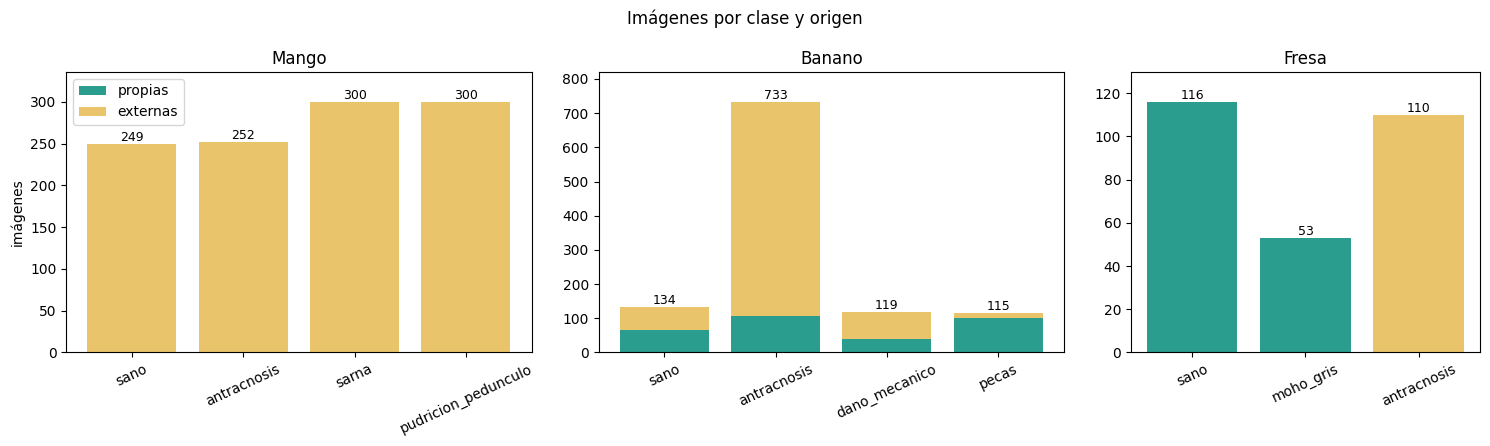

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={"width_ratios": [4, 4, 3]})
for ax, (fruta, clases) in zip(axes, ORDEN.items()):
    d = por_clase[por_clase["fruta"] == fruta].set_index("clase").loc[clases]
    ax.bar(clases, d["propias"], color=COLOR_ORIGEN["propia"], label="propias")
    ax.bar(clases, d["externas"], bottom=d["propias"], color=COLOR_ORIGEN["externa"], label="externas")
    for i, total in enumerate(d["total"]):
        ax.text(i, total, str(total), ha="center", va="bottom", fontsize=9)
    ax.set_title(fruta.capitalize())
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(0, d["total"].max() * 1.12)
axes[0].set_ylabel("imágenes")
axes[0].legend()
fig.suptitle("Imágenes por clase y origen")
fig.tight_layout()
fig.savefig(FIGURAS / "imagenes_por_clase.png", dpi=120)
plt.show()

### 8.4. Balance de clases

La razón entre la clase más grande y la más pequeña de cada fruta mide qué tan desbalanceado está el conjunto. Una razón de 1 indica clases del mismo tamaño.

In [14]:
balance = por_clase.groupby("fruta", sort=False)["total"].agg(clase_menor="min", clase_mayor="max")
balance["razon_mayor_menor"] = (balance["clase_mayor"] / balance["clase_menor"]).round(2)
balance

,clase_menor,clase_mayor,razon_mayor_menor
fruta,,,
mango,249,300,1.20
banano,115,733,6.37
fresa,53,116,2.19


### 8.5. Origen de las imágenes

Cuántas imágenes aporta cada fuente a cada fruta, y quién tomó las fotos propias.

In [15]:
pd.crosstab(etiquetas["fuente"], etiquetas["fruta"], margins=True, margins_name="total")[["mango", "banano", "fresa", "total"]]

fruta,mango,banano,fresa,total
fuente,,,,
Banana and Banana Leaf Dataset (Mendeley Data),0,759,0,759
Externa sin identificar,0,13,0,13
Externa sin identificar (cámara OPPO),0,15,0,15
MangoDHDS (Mendeley Data),1101,0,0,1101
Propia,0,314,169,483
Roboflow,0,0,110,110
total,1101,1101,279,2481


In [16]:
propias = etiquetas[etiquetas["origen"] == "propia"]
pd.crosstab(propias["integrante"], propias["fruta"], margins=True, margins_name="total")[["banano", "fresa", "total"]]

fruta,banano,fresa,total
integrante,,,
Andrés Arbeláez,112,57,169
Diego Cifuentes,137,17,154
Sara Suárez,0,68,68
Sofía Giraldo,65,27,92
total,314,169,483


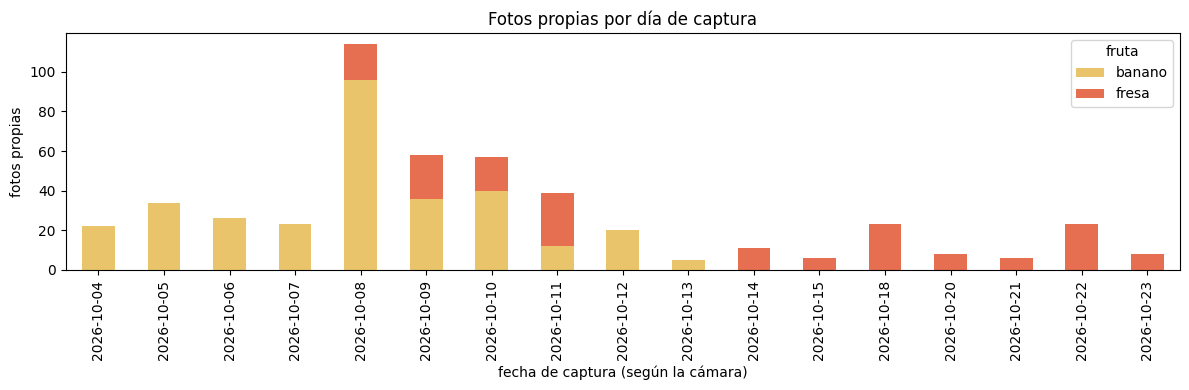

In [17]:
fechas = pd.crosstab(propias["fecha_captura"], propias["fruta"])[["banano", "fresa"]]
ax = fechas.plot(kind="bar", stacked=True, figsize=(12, 4), color=["#e9c46a", "#e76f51"])
ax.set_xlabel("fecha de captura (según la cámara)")
ax.set_ylabel("fotos propias")
ax.set_title("Fotos propias por día de captura")
plt.tight_layout()
plt.savefig(FIGURAS / "fotos_propias_por_dia.png", dpi=120)
plt.show()

### 8.6. Tamaño de las imágenes

Las imágenes propias y algunas externas se redujeron a 1024 px en su lado mayor; las demás conservan el tamaño de su fuente.

In [18]:
etiquetas["tamano"] = etiquetas["ancho"].astype(str) + " × " + etiquetas["alto"].astype(str)
etiquetas["lado_mayor"] = etiquetas[["ancho", "alto"]].max(axis=1)
tamanos = (
    etiquetas.groupby(["fruta", "fuente"], sort=False)
    .agg(imagenes=("archivo", "size"),
         tamano_mas_comun=("tamano", lambda s: s.value_counts().index[0]),
         tamanos_distintos=("tamano", "nunique"),
         lado_mayor_min=("lado_mayor", "min"),
         lado_mayor_max=("lado_mayor", "max"))
)
tamanos

imagenes  \
fruta  fuente                                                     
banano Propia                                               314   
       Banana and Banana Leaf Dataset (Mendeley Data)       759   
       Externa sin identificar                               13   
       Externa sin identificar (cámara OPPO)                 15   
fresa  Roboflow                                             110   
       Propia                                               169   
mango  MangoDHDS (Mendeley Data)                           1101   

                                                      tamano_mas_comun  \
fruta  fuente                                                            
banano Propia                                               1024 × 768   
       Banana and Banana Leaf Dataset (Mendeley Data)       1000 × 750   
       Externa sin identificar                               640 × 480   
       Externa sin identificar (cámara OPPO)                1024 × 768   
fresa  Roboflow                                              419 × 419   
       Propia                                               1024 × 768   
mango  MangoDHDS (Mendeley Data)                             256 × 256   

                                                       tamanos_distintos  \
fruta  fuente                                                              
banano Propia                                                          2   
       Banana and Banana Leaf Dataset (Mendeley Data)                  2   
       Externa sin identificar                                         3   
       Externa sin identificar (cámara OPPO)                           2   
fresa  Roboflow                                                        2   
       Propia                                                          3   
mango  MangoDHDS (Mendeley Data)                                       1   

                                                       lado_mayor_min  \
fruta  fuente                                                           
banano Propia                                                    1024   
       Banana and Banana Leaf Dataset (Mendeley Data)            1000   
       Externa sin identificar                                    520   
       Externa sin identificar (cámara OPPO)                     1024   
fresa  Roboflow                                                   419   
       Propia                                                    1024   
mango  MangoDHDS (Mendeley Data)                                  256   

                                                       lado_mayor_max  
fruta  fuente                                                          
banano Propia                                                    1024  
       Banana and Banana Leaf Dataset (Mendeley Data)            1000  
       Externa sin identificar                                    640  
       Externa sin identificar (cámara OPPO)                     1024  
fresa  Roboflow                                                   640  
       Propia                                                    1024  
mango  MangoDHDS (Mendeley Data)                                  256

### 8.7. Color y fondo de cada imagen

Para cada imagen se calculan, sobre una versión reducida a 256 px:

- **Brillo del borde:** promedio de gris (0 a 255) en una franja del 5 % junto a los cuatro bordes. Como la fruta suele estar en el centro, este valor describe el fondo.
- **Histograma de tono:** histograma del canal H del modelo HSV (36 intervalos de 10°), contando solo píxeles con saturación y brillo suficientes para excluir fondos blancos, grises o negros.

In [19]:
def describir_imagen(ruta, bins=36):
    with Image.open(ruta) as im:
        im.draft("RGB", (256, 256))              # decodificación rápida a tamaño reducido
        im = ImageOps.contain(im.convert("RGB"), (256, 256))
    gris = np.asarray(im.convert("L"), dtype=float)
    alto, ancho = gris.shape
    b = max(1, int(0.05 * min(alto, ancho)))
    borde = np.concatenate([gris[:b].ravel(), gris[-b:].ravel(), gris[:, :b].ravel(), gris[:, -b:].ravel()])
    h, s, v = np.moveaxis(np.asarray(im.convert("HSV"), dtype=float), -1, 0)
    mascara = (s > 64) & (v > 50)              # descarta fondos poco saturados u oscuros
    hist, _ = np.histogram(h[mascara] * 360 / 256, bins=bins, range=(0, 360))
    return borde.mean(), gris.mean(), hist / max(hist.sum(), 1)

resultados = [describir_imagen(DATASET / a) for a in etiquetas["archivo"]]
etiquetas["brillo_borde"] = [r[0] for r in resultados]
etiquetas["brillo_medio"] = [r[1] for r in resultados]
hist_tono = np.stack([r[2] for r in resultados])
print("Imágenes procesadas:", len(resultados))

Imágenes procesadas: 2481


### 8.8. Fondo de las fotos según su fuente

Cada fuente fotografió las frutas sobre un fondo distinto. Si una clase proviene casi toda de una sola fuente, el modelo puede aprender a reconocer el fondo en vez de la lesión.

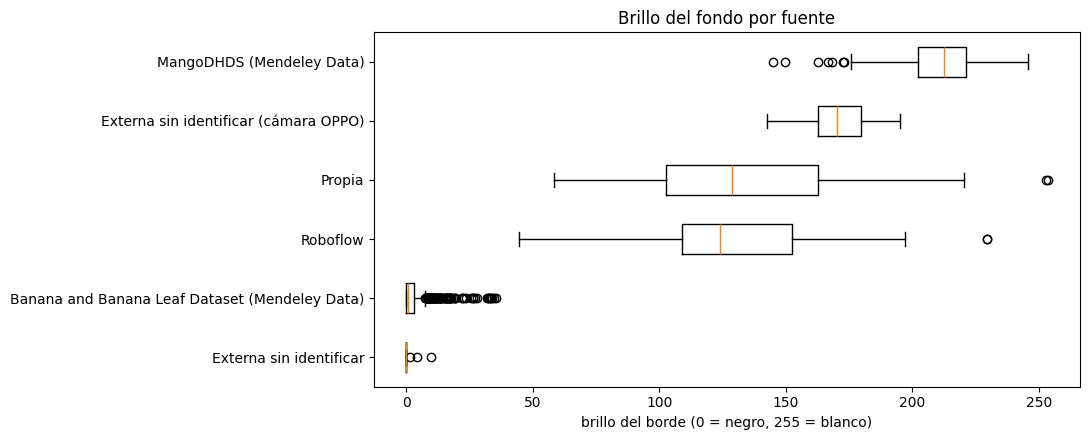

In [20]:
fuentes = etiquetas.groupby("fuente")["brillo_borde"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([etiquetas.loc[etiquetas["fuente"] == f, "brillo_borde"] for f in fuentes], vert=False)
ax.set_yticks(range(1, len(fuentes) + 1))
ax.set_yticklabels(fuentes)
ax.set_xlabel("brillo del borde (0 = negro, 255 = blanco)")
ax.set_title("Brillo del fondo por fuente")
plt.tight_layout()
plt.savefig(FIGURAS / "brillo_fondo_por_fuente.png", dpi=120)
plt.show()

In [21]:
etiquetas["fondo_oscuro"] = etiquetas["brillo_borde"] < 50
fondo = (
    etiquetas.groupby(["fruta", "clase"], sort=False)
    .agg(imagenes=("archivo", "size"),
         pct_propias=("origen", lambda s: round(100 * (s == "propia").mean(), 1)),
         pct_fondo_oscuro=("fondo_oscuro", lambda s: round(100 * s.mean(), 1)),
         brillo_borde_mediana=("brillo_borde", lambda s: round(s.median(), 1)))
)
fondo.loc[[(f, c) for f, clases in ORDEN.items() for c in clases]]

imagenes  pct_propias  pct_fondo_oscuro  \
fruta  clase                                                          
mango  sano                      249          0.0               0.0   
       antracnosis               252          0.0               0.0   
       sarna                     300          0.0               0.0   
       pudricion_pedunculo       300          0.0               0.0   
banano sano                      134         49.3              50.7   
       antracnosis               733         14.7              85.3   
       dano_mecanico             119         33.6              66.4   
       pecas                     115         87.0               0.0   
fresa  sano                      116        100.0               0.0   
       moho_gris                  53        100.0               0.0   
       antracnosis               110          0.0               1.8   

                            brillo_borde_mediana  
fruta  clase                                      
mango  sano                                210.3  
       antracnosis                         219.1  
       sarna                               207.8  
       pudricion_pedunculo                 213.0  
banano sano                                  9.3  
       antracnosis                           0.7  
       dano_mecanico                         7.4  
       pecas                               132.1  
fresa  sano                                117.5  
       moho_gris                           194.8  
       antracnosis                         123.9

### 8.9. Histograma de tono por clase

Promedio, por clase, del histograma de tono de sus imágenes. Muestra qué colores dominan en la fruta de cada clase.

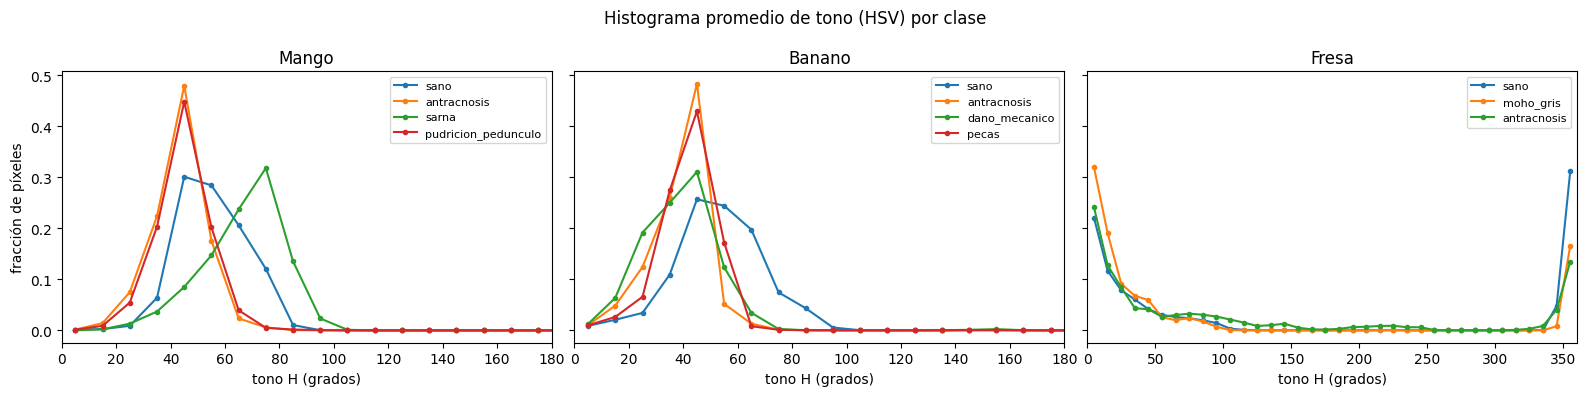

In [22]:
centros = np.arange(5, 360, 10)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (fruta, clases) in zip(axes, ORDEN.items()):
    for clase in clases:
        idx = ((etiquetas["fruta"] == fruta) & (etiquetas["clase"] == clase)).to_numpy()
        ax.plot(centros, hist_tono[idx].mean(axis=0), marker=".", label=clase)
    ax.set_title(fruta.capitalize())
    ax.set_xlabel("tono H (grados)")
    ax.set_xlim(0, 360 if fruta == "fresa" else 180)   # el rojo de la fresa está cerca de 0° y de 360°
    ax.legend(fontsize=8)
axes[0].set_ylabel("fracción de píxeles")
fig.suptitle("Histograma promedio de tono (HSV) por clase")
fig.tight_layout()
fig.savefig(FIGURAS / "histograma_tono_por_clase.png", dpi=120)
plt.show()

### 8.10. Mosaico de muestra

Ocho imágenes al azar por clase: hasta cuatro propias y el resto externas. Las imágenes se recortan al centro en formato cuadrado solo para el mosaico.

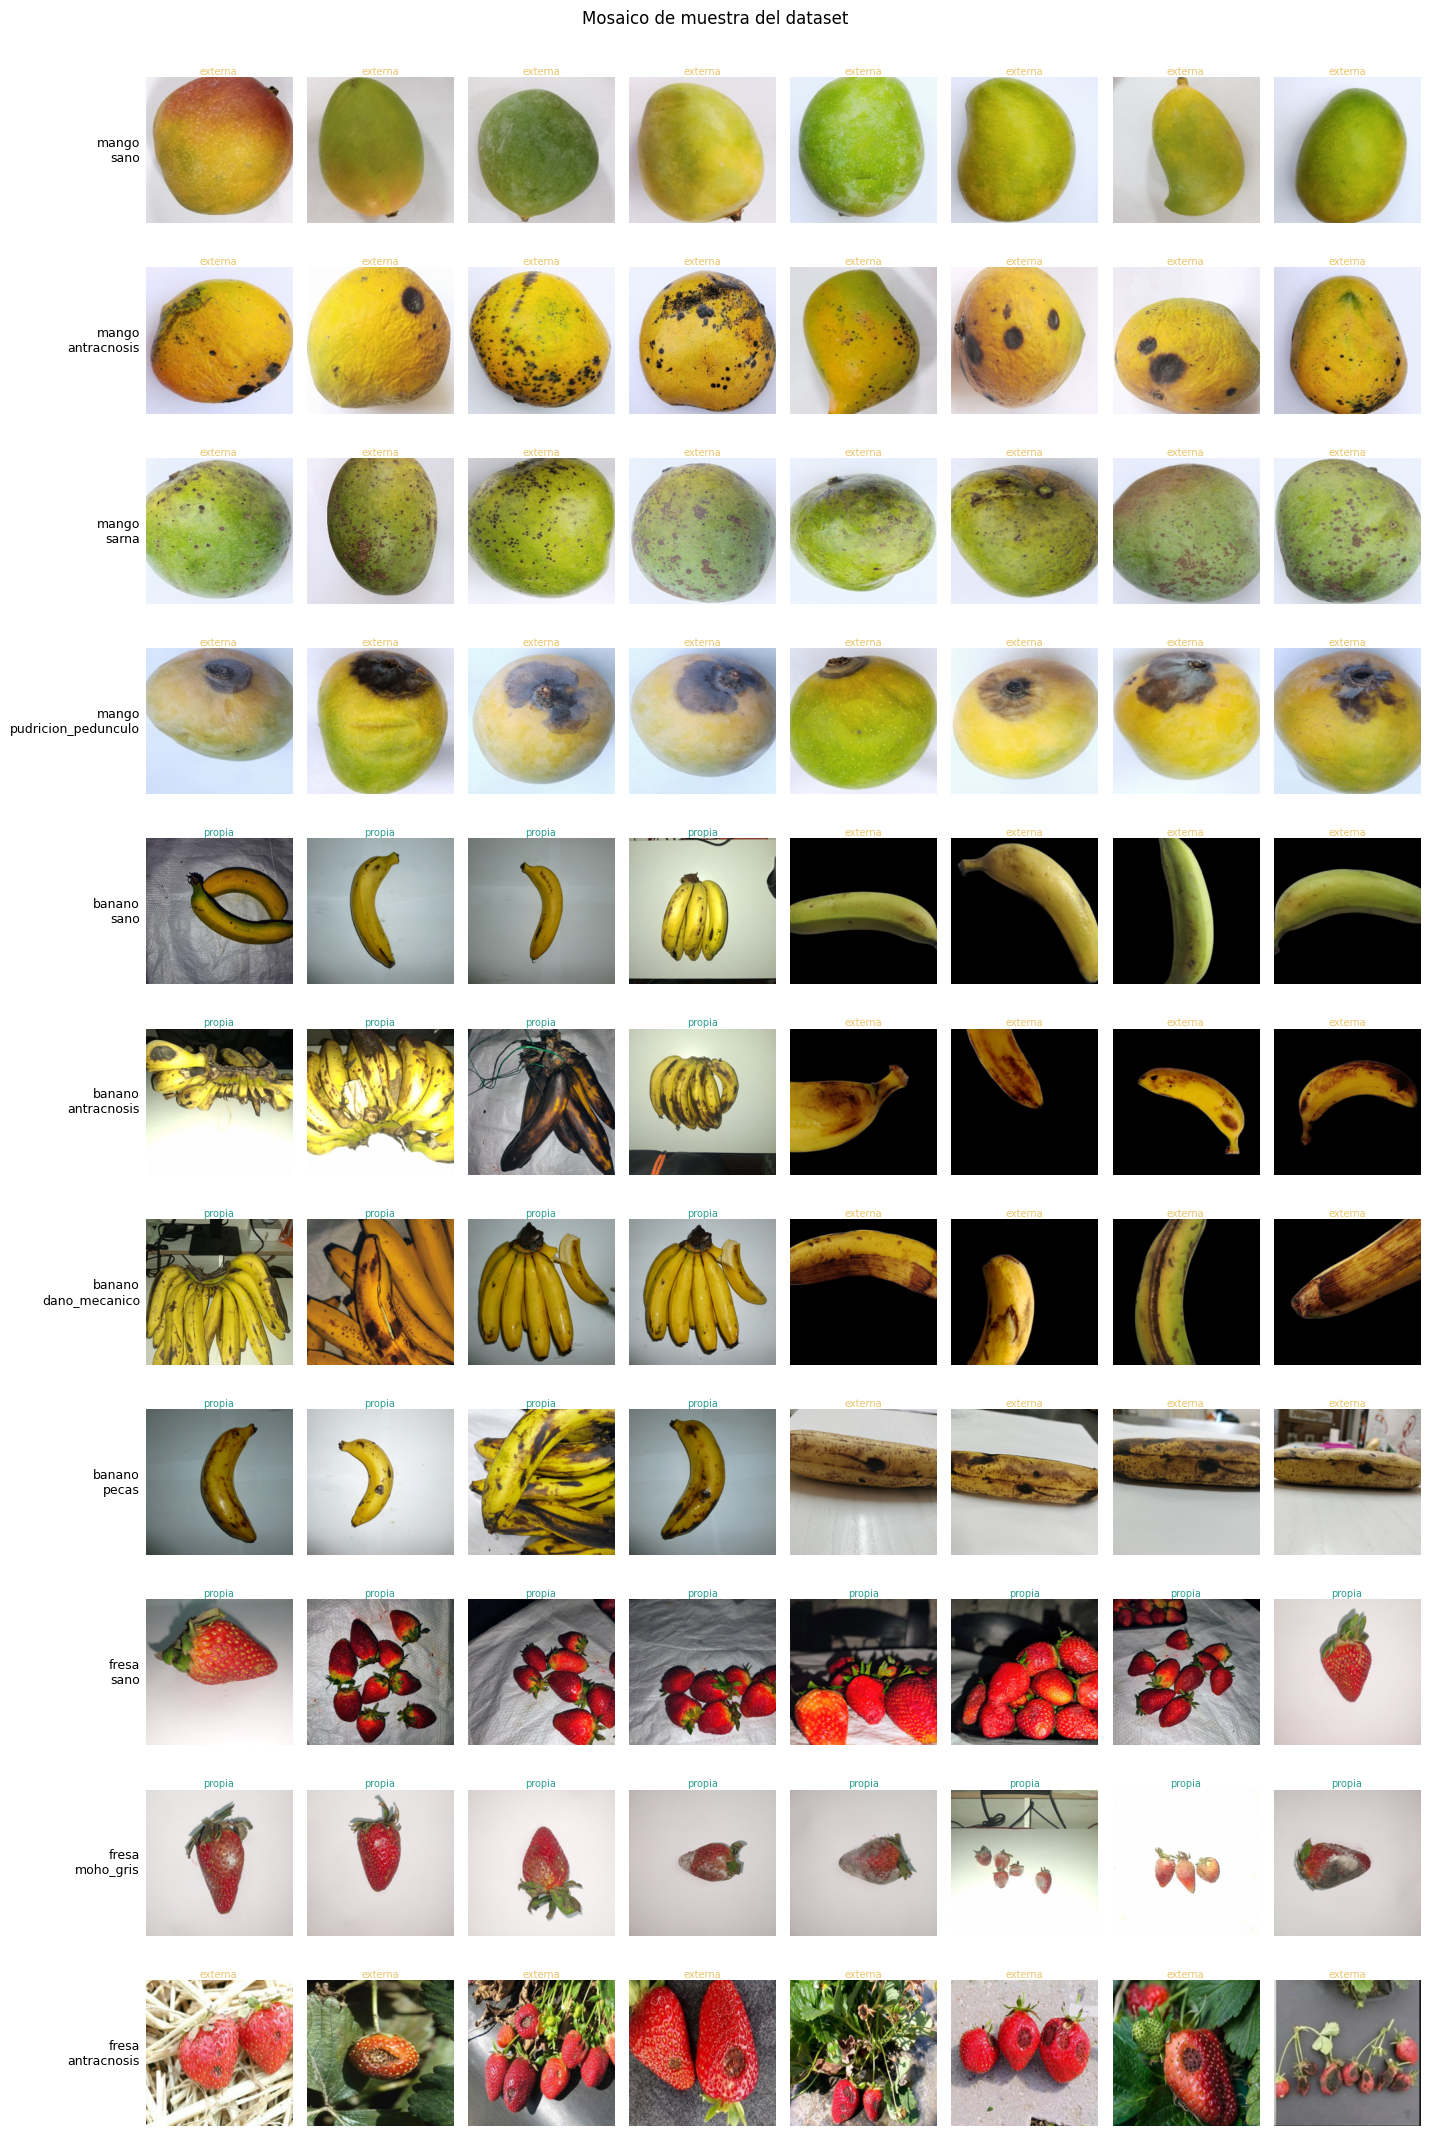

In [23]:
POR_CLASE = 8
rng = np.random.default_rng(SEMILLA)
filas_mosaico = [(f, c) for f, clases in ORDEN.items() for c in clases]

fig, axes = plt.subplots(len(filas_mosaico), POR_CLASE, figsize=(POR_CLASE * 1.8, len(filas_mosaico) * 1.95))
for i, (fruta, clase) in enumerate(filas_mosaico):
    d = etiquetas[(etiquetas["fruta"] == fruta) & (etiquetas["clase"] == clase)]
    propias_c = d[d["origen"] == "propia"]
    externas_c = d[d["origen"] == "externa"]
    n_propias = min(len(propias_c), POR_CLASE // 2 if len(externas_c) else POR_CLASE)
    n_externas = min(len(externas_c), POR_CLASE - n_propias)
    muestra = pd.concat([
        propias_c.iloc[rng.choice(len(propias_c), n_propias, replace=False)],
        externas_c.iloc[rng.choice(len(externas_c), n_externas, replace=False)],
    ])
    for j, ax in enumerate(axes[i]):
        ax.set_xticks([])
        ax.set_yticks([])
        for lado in ax.spines.values():
            lado.set_visible(False)
        if j < len(muestra):
            fila = muestra.iloc[j]
            with Image.open(DATASET / fila["archivo"]) as im:
                ax.imshow(ImageOps.fit(im.convert("RGB"), (220, 220)))
            ax.set_title(fila["origen"], fontsize=7, color=COLOR_ORIGEN[fila["origen"]], pad=2)
    axes[i, 0].set_ylabel(f"{fruta}\n{clase}", fontsize=9, rotation=0, ha="right", va="center")
fig.suptitle("Mosaico de muestra del dataset", y=1.0)
fig.tight_layout()
fig.savefig(FIGURAS / "mosaico_dataset.jpg", dpi=100, bbox_inches="tight")
plt.show()

### 8.11. Imágenes excluidas

Resumen de `excluidas.csv` por motivo y fruta.

In [24]:
motivo = excluidas["motivo"].str.replace(r"^Duplicado exacto de .*", "Duplicado exacto", regex=True)
motivo = motivo.str.replace(r"^Misma imagen en dos clases: .*", "Misma imagen en dos clases", regex=True)
pd.crosstab(motivo, excluidas["fruta"], margins=True, margins_name="total")

fruta,banano,fresa,mango,total
motivo,,,,
Clase descartada: pudrición de corona,36,0,0,36
Duplicado exacto,30,40,99,169
"Foto de stock aumentada, sin la imagen original",163,0,0,163
Fresa con varias etiquetas o fuera de las tres clases,0,274,0,274
Misma imagen en dos clases,6,0,0,6
total,235,314,99,648


### 8.12. Hallazgos

Con los datos y gráficos de esta sección:

1. **Cantidad.** El dataset tiene 2.481 imágenes: 1.101 de mango, 1.101 de banano y 279 de fresa. Las fotos propias son 483, el 19,5 % del total: 0 % del mango, 28,5 % del banano y 60,6 % de la fresa.
2. **Balance.** El mango está casi balanceado (razón 1,20 entre su clase mayor y su clase menor). El banano no: antracnosis tiene 733 imágenes, el 66,6 % de la fruta, y su razón con pecas (115) es 6,37. En la fresa la razón es 2,19, con moho gris como la clase menor (53).
3. **Origen por clase en banano.** La proporción de fotos propias cambia mucho entre clases: 87,0 % en pecas, 49,3 % en sano, 33,6 % en daño mecánico y 14,7 % en antracnosis.
4. **Fondo.** Las externas del *Banana and Banana Leaf Dataset* tienen fondo negro, igual que las 13 externas sin identificar; las propias tienen fondos claros o grises. Por eso el porcentaje de imágenes con fondo oscuro también cambia por clase: 85,3 % en antracnosis, 66,4 % en daño mecánico, 50,7 % en sano y 0 % en pecas. Un modelo podría aprender a distinguir el fondo en vez de la lesión. Para controlarlo se puede segmentar la fruta y quitar el fondo antes de clasificar, y medir el desempeño por separado para cada fuente.
5. **Tamaño y encuadre.** Cada fuente tiene un tamaño distinto: 256 × 256 px en MangoDHDS, 419 × 419 en Roboflow, 1000 × 750 en el dataset de banano y 1024 px en el lado mayor de las propias. Además, el mango aparece como un solo fruto que llena el cuadro, mientras que muchas fotos propias de banano muestran la mano completa. Todas las imágenes deberán llevarse a un mismo tamaño de entrada.
6. **Color.** En el banano, la clase sana tiene más píxeles en tonos verdes (60° a 90°) que las demás. En el mango, la sarna es la clase más verde, mientras que la antracnosis y la pudrición del pedúnculo se concentran en amarillo-naranja, cerca de 45°. El color aporta información, pero también refleja el grado de maduración de cada fruta.
7. **Fresa.** Cada clase de fresa proviene de una sola fuente: sano y moho gris son solo fotos propias, y antracnosis solo imágenes de Roboflow, tomadas en campo y con hojas. Por eso la fresa se documenta pero no entra al modelo de esta entrega.
8. **Series en el tiempo.** Las fotos propias siguen las mismas frutas durante varios días. Por eso la partición de la sección 7 no las reparte al azar: las de Sofía Giraldo van todas a test y las de Andrés Arbeláez y Diego Cifuentes se reparten por sesión entre train y validation.